# Você sobreviveria ao Titanic? 🚢
## Etapa 2 — KNN: desafio dos hiperparâmetros

Nesta aula, você treinará um modelo de classificação com dados históricos do Titanic, comparará diferentes escolhas de KNN e, no final, usará o **cartão de embarque impresso** para prever a sobrevivência de um perfil fictício.

**Objetivo didático:** previsões são estimativas estatísticas, não certezas.

## 1. Problema e características
**Pergunta:** com base em informações conhecidas sobre um passageiro, conseguimos estimar se ele teria sobrevivido?

Usaremos: classe, sexo, idade, número de irmãos/cônjuges a bordo, pais/filhos a bordo, tarifa e porto de embarque. Não usaremos nome, número da passagem ou identificação. A coluna cabine será deixada de fora inicialmente devido ao alto número de valores ausentes.

**Atenção:** trata-se de uma análise histórica de associações, não de uma previsão causal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

# No Colab, faça upload do train.csv quando solicitado.
from pathlib import Path
if not Path('train.csv').exists():
    from google.colab import files
    files.upload()

df = pd.read_csv('train.csv')
print('Dimensões:', df.shape)
display(df.head())

Saving train.csv to train.csv
Dimensões: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Seleção das variáveis e separação 80/20
Dividimos **antes** de aprender valores para preencher dados ausentes e padronizar escalas. Assim, a validação não influencia o preparo do treino.

In [2]:
colunas_numericas = ['Age', 'SibSp', 'Parch', 'Fare']
colunas_categoricas = ['Pclass', 'Sex', 'Embarked']
atributos = colunas_numericas + colunas_categoricas
X = df[atributos].copy()
y = df['Survived'].copy()

X_treino, X_validacao, y_treino, y_validacao = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Treino:', len(X_treino), '| Validação:', len(X_validacao))
print('Taxa de sobrevivência no treino:', round(y_treino.mean() * 100, 1), '%')
print('Taxa de sobrevivência na validação:', round(y_validacao.mean() * 100, 1), '%')

Treino: 712 | Validação: 179
Taxa de sobrevivência no treino: 38.3 %
Taxa de sobrevivência na validação: 38.5 %


## 3. Pipeline: preparar dados e classificar
O KNN calcula distâncias. Por isso, precisamos tratar valores ausentes, padronizar variáveis numéricas e transformar categorias em números. A preparação é aprendida **apenas com o treino**.

`StandardScaler` padroniza (não é normalização min–max). `OneHotEncoder` evita atribuir uma ordem artificial a sexo, classe e porto.

In [3]:
def criar_modelo(k=5, pesos='uniform', p=2):
    preparo = ColumnTransformer([
        ('numericas', make_pipeline(
            SimpleImputer(strategy='median'), StandardScaler()
        ), colunas_numericas),
        ('categoricas', make_pipeline(
            SimpleImputer(strategy='most_frequent'),
            OneHotEncoder(handle_unknown='ignore')
        ), colunas_categoricas)
    ])
    return make_pipeline(preparo, KNeighborsClassifier(
        n_neighbors=k, weights=pesos, p=p
    ))

## 4. Primeiro KNN: referência propositalmente simples
Começaremos com **K = 75**, `weights="uniform"` e `p=2`. É um ponto de partida com muitos vizinhos, que pode suavizar demais as decisões. **Não é garantido que seja o pior modelo**, mas o desafio é tentar superar sua acurácia de validação. Não altere o conjunto de validação durante a atividade.


In [4]:
modelo_referencia = criar_modelo(k=75, pesos='uniform', p=2)
modelo_referencia.fit(X_treino, y_treino)
print('Acurácia no treino:', f'{modelo_referencia.score(X_treino, y_treino):.1%}')
print('Acurácia na validação:', f'{modelo_referencia.score(X_validacao, y_validacao):.1%}')


Acurácia no treino: 77.4%
Acurácia na validação: 72.6%


**Discuta:** a acurácia de referência é suficiente para concluir que encontramos a melhor configuração? Por quê?

## 5. Entendendo os hiperparâmetros
- **`n_neighbors` (K):** quantos exemplos semelhantes participam da votação. K muito pequeno pode ajustar demais os dados; K muito grande pode suavizar excessivamente.
- **`weights`:** `uniform` dá o mesmo voto a todos os vizinhos; `distance` dá maior peso aos mais próximos.
- **`p`:** com a distância de Minkowski, `p=1` corresponde à distância Manhattan e `p=2` à euclidiana.

Não existe um valor universalmente melhor: vamos **comparar os resultados na validação**.

## Visualização: como K muda a decisão
Esta figura didática usa **pontos ilustrativos**, não dados do Titanic. O ponto em estrela representa um novo perfil. Compare o resultado com K=1, K=5 e K=15. No modelo real, as distâncias são calculadas após o pré-processamento, considerando todas as características.


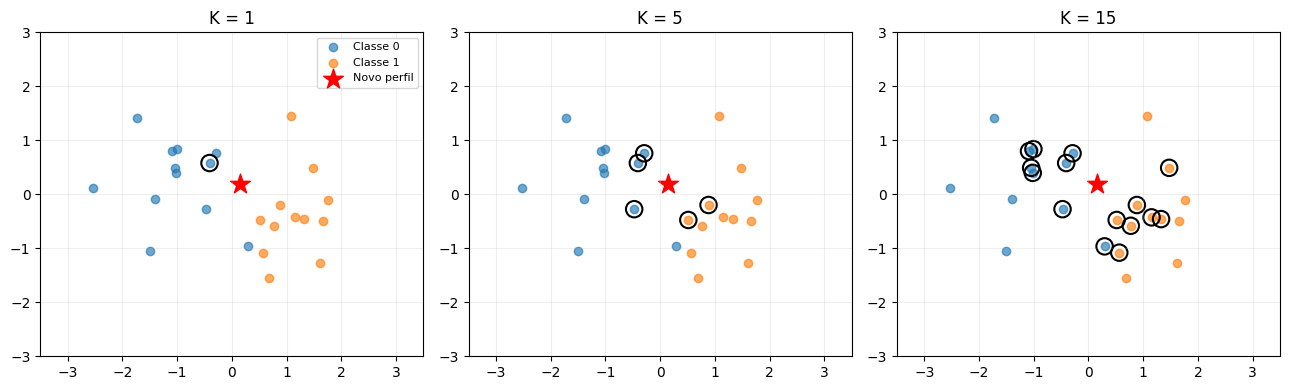

In [6]:
# Ilustração em duas dimensões: vizinhos de um novo perfil
from sklearn.neighbors import NearestNeighbors
rng = np.random.default_rng(12)
pontos = np.vstack([rng.normal([-1, 0], .8, (12, 2)),
                    rng.normal([1, 0], .8, (12, 2))])
classes = np.array([0]*12 + [1]*12)
novo = np.array([[.15, .2]])
fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
for ax, k in zip(eixos, [1, 5, 15]):
    vizinhos = NearestNeighbors(n_neighbors=k).fit(pontos)
    indices = vizinhos.kneighbors(novo, return_distance=False)[0]
    ax.scatter(pontos[classes == 0, 0], pontos[classes == 0, 1], label='Classe 0', alpha=.65)
    ax.scatter(pontos[classes == 1, 0], pontos[classes == 1, 1], label='Classe 1', alpha=.65)
    ax.scatter(pontos[indices, 0], pontos[indices, 1], s=140,
               facecolors='none', edgecolors='black', linewidths=1.5)
    ax.scatter(novo[:, 0], novo[:, 1], marker='*', s=220, color='red', label='Novo perfil')
    ax.set_title(f'K = {k}')
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3, 3); ax.grid(alpha=.2)
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 6. Desafio: seis configurações escolhidas pela turma
A primeira linha é a referência. **Preencha as outras cinco** com combinações de `k`, `pesos` e `p` antes de executar.

**Objetivo:** superar a acurácia de validação da referência e explicar por que o resultado mudou. K=1 pode acertar muito no treino sem generalizar. Evite alterar o split para buscar um resultado melhor.


In [111]:
# Complete as cinco configurações com valores escolhidos por você.
# Use K inteiro positivo, pesos = 'uniform' ou 'distance', p = 1 ou 2.
configuracoes = [
    {'nome': '1 - Referência', 'k': 75, 'pesos': 'uniform', 'p': 2},
    {'nome': '2 - Minha escolha 1', 'k': 55, 'pesos': 'distance', 'p': 2},  # ALTERE
    {'nome': '3 - Minha escolha 2', 'k': 65, 'pesos': 'uniform', 'p': 1},  # ALTERE
    {'nome': '4 - escolha da Carla ', 'k': 38, 'pesos': 'uniform', 'p': 1},  # ALTERE
    {'nome': '5 - escolha do tadeu', 'k': 36, 'pesos': 'uniform', 'p': 1},  # ALTERE
    {'nome': '6 - Minha escolha 3', 'k': 70, 'pesos': 'uniform', 'p': 2},  # ALTERE
]

resultados = []
modelos = {}
for cfg in configuracoes:
    modelo = criar_modelo(cfg['k'], cfg['pesos'], cfg['p'])
    modelo.fit(X_treino, y_treino)
    modelos[cfg['nome']] = modelo
    resultados.append({
        'Configuração': cfg['nome'], 'K': cfg['k'],
        'Pesos': cfg['pesos'], 'p': cfg['p'],
        'Treino': modelo.score(X_treino, y_treino),
        'Validação': modelo.score(X_validacao, y_validacao)
    })
comparacao = pd.DataFrame(resultados)
display(comparacao.style.format({'Treino': '{:.1%}', 'Validação': '{:.1%}'}))


,Configuração,K,Pesos,p,Treino,Validação
0,1 - Referência,75,uniform,2,77.4%,72.6%
1,2 - Minha escolha 1,55,distance,2,98.3%,77.7%
2,3 - Minha escolha 2,65,uniform,1,81.7%,80.4%
3,4 - escolha da Carla,38,uniform,1,81.5%,81.0%
4,5 - escolha do tadeu,36,uniform,1,81.9%,81.6%
5,6 - Minha escolha 3,70,uniform,2,77.5%,73.2%


## 7. Visualização: treino × validação
**Perguntas:** qual configuração apresentou a maior acurácia na validação? Alguma mostrou uma diferença grande entre treino e validação? Isso pode indicar overfitting?

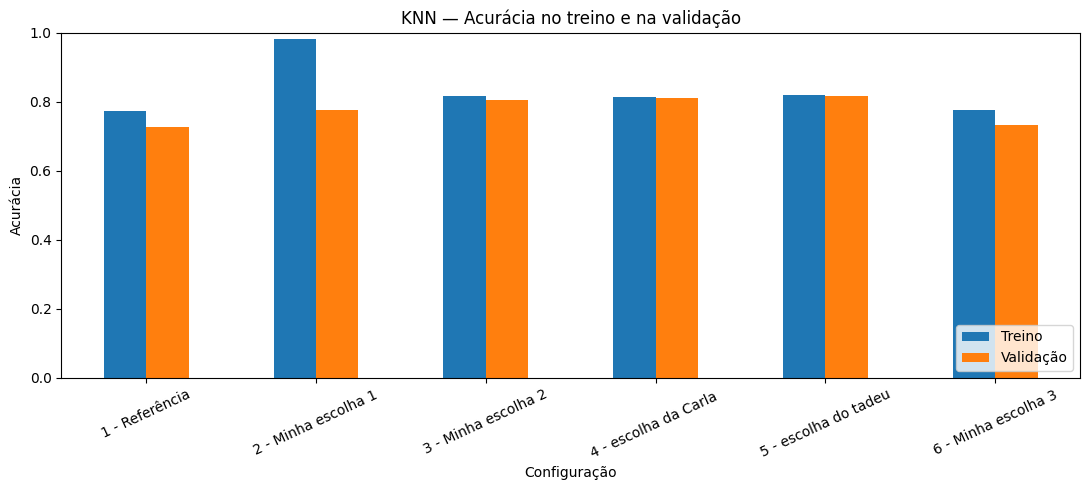

In [112]:
ax = comparacao.set_index('Configuração')[['Treino', 'Validação']].plot(
    kind='bar', figsize=(11, 5), ylim=(0, 1), rot=25
)
ax.set_ylabel('Acurácia')
ax.set_title('KNN — Acurácia no treino e na validação')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 8. Selecionar a melhor das seis configurações
Usamos a **maior acurácia de validação** como critério de escolha. Em caso de empate, usamos a ordem em que as configurações foram apresentadas. Esta é a melhor **entre as seis testadas**, não necessariamente a melhor possível.

**Nota:** como a validação foi consultada para selecionar hiperparâmetros, uma avaliação final independente exigiria outro conjunto de teste.

In [113]:
indice_melhor = comparacao['Validação'].idxmax()
nome_melhor = comparacao.loc[indice_melhor, 'Configuração']
melhor_modelo = modelos[nome_melhor]
print('Configuração escolhida:', nome_melhor)
print('Acurácia na validação:', f"{comparacao.loc[indice_melhor, 'Validação']:.1%}")

Configuração escolhida: 5 - escolha do tadeu
Acurácia na validação: 81.6%


## 9. Matriz de confusão e análise de erros
Considere **1 = sobreviveu** como classe positiva. Analise verdadeiros positivos, verdadeiros negativos, falsos positivos e falsos negativos.

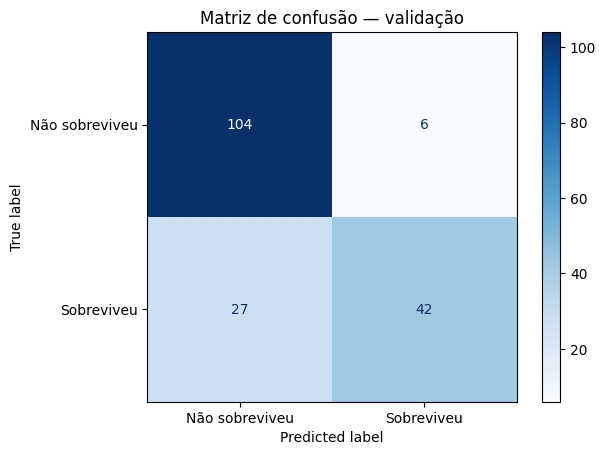

                precision    recall  f1-score   support

Não sobreviveu       0.79      0.95      0.86       110
    Sobreviveu       0.88      0.61      0.72        69

      accuracy                           0.82       179
     macro avg       0.83      0.78      0.79       179
  weighted avg       0.83      0.82      0.81       179



In [114]:
previsoes = melhor_modelo.predict(X_validacao)
ConfusionMatrixDisplay.from_predictions(
    y_validacao, previsoes, display_labels=['Não sobreviveu', 'Sobreviveu'],
    cmap='Blues', values_format='d'
)
plt.title('Matriz de confusão — validação')
plt.show()
print(classification_report(
    y_validacao, previsoes, target_names=['Não sobreviveu', 'Sobreviveu'],
    zero_division=0
))

## 10. Inspecionar alguns erros
Compare características dos passageiros classificados incorretamente. Uma previsão errada não significa que o registro histórico esteja errado.

In [115]:
analise = X_validacao.copy()
analise['Real'] = y_validacao
analise['Previsto'] = previsoes
incorretos = analise[analise['Real'] != analise['Previsto']]
print('Erros encontrados:', len(incorretos))
display(incorretos.head(10))

Erros encontrados: 33


,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Real,Previsto
553,22.0,0,0,7.2250,3,male,C,1,0
559,36.0,1,0,17.4000,3,female,S,1,0
698,49.0,1,1,110.8833,1,male,C,0,1
216,27.0,0,0,7.9250,3,female,S,1,0
279,35.0,1,1,20.2500,3,female,S,1,0
712,48.0,1,0,52.0000,1,male,S,1,0
455,29.0,0,0,7.8958,3,male,C,1,0
65,NaN,1,1,15.2458,3,male,C,1,0
489,9.0,1,1,15.9000,3,male,S,1,0
869,4.0,1,1,11.1333,3,male,S,1,0


## 11. Cartão de embarque — você sobreviveria ao Titanic?

Pegue o **cartão impresso preenchido na aula**. Transcreva as sete informações para as variáveis do código abaixo e execute. O modelo prevê o resultado com base em passageiros semelhantes.

**Como preencher:** sexo `female` (feminino) ou `male` (masculino); classe `1`, `2` ou `3`; porto `S` (Southampton), `C` (Cherbourg) ou `Q` (Queenstown); tarifa em libras (£). Irmãos/cônjuge e pais/filhos são **contagens**.

Depois, anote no cartão o resultado. Compare com colegas: quais características diferentes podem ter influenciado a previsão? **Não interprete a probabilidade como garantia histórica.**

In [156]:
# Transcreva os dados do SEU CARTÃO DE EMBARQUE (perfil fictício).
# Altere os valores abaixo e execute novamente.
idade = 20
sexo = 'male'            # 'female' ou 'male'
classe = 2           # 1, 2 ou 3
irmaos_conjuges = 0
pais_filhos = 0
tarifa = 300
porto = 'Q'                # 'S', 'C' ou 'Q'

novo_passageiro = pd.DataFrame([{
    'Age': idade, 'SibSp': irmaos_conjuges, 'Parch': pais_filhos,
    'Fare': tarifa, 'Pclass': classe, 'Sex': sexo, 'Embarked': porto
}])
resultado = int(melhor_modelo.predict(novo_passageiro)[0])
print('Previsão:', 'Sobreviveu' if resultado == 1 else 'Não sobreviveu')
print('Probabilidades estimadas pelo KNN:',
      dict(zip(['Não sobreviveu', 'Sobreviveu'],
               melhor_modelo.predict_proba(novo_passageiro)[0].round(3))))

Previsão: Não sobreviveu
Probabilidades estimadas pelo KNN: {'Não sobreviveu': np.float64(0.833), 'Sobreviveu': np.float64(0.167)}


## 12. Exercícios para discussão
1. Qual configuração teve a maior acurácia de **treinamento**? Ela também foi a melhor na **validação**?
2. O que aconteceu com K = 1? Relacione com overfitting.
3. Aumentar K para 15 sempre melhorou a validação? Justifique com os resultados.
4. O que mudou ao utilizar `weights='distance'`?
5. Qual diferença apareceu entre `p=1` e `p=2`?
6. Qual configuração você escolheria entre as seis? Por quê?
7. Cite um falso positivo e um falso negativo na matriz de confusão. O que cada um significa neste problema?
8. Altere o sexo, mantendo os outros campos do formulário. A previsão mudou? Isso prova causalidade?
9. Por que os 20% usados para escolher a configuração **não** constituem um teste final independente?

**Conclusão:** o objetivo não é decorar parâmetros, mas **testar, comparar, interpretar e justificar decisões**.

### Desafio final com o cartão
1. O seu perfil sobreviveu segundo o KNN? Registre a previsão no cartão.
2. Troque **apenas uma característica** (por exemplo, classe) e execute novamente. A previsão mudou?
3. Por que uma mudança na previsão não prova que essa característica causou a sobrevivência?
